<a href="https://colab.research.google.com/github/amart488-sudo/Phys133-lab-2-code/blob/main/Lab_2_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [76]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math
import sympy as sp
from scipy.special import factorial

In [77]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [78]:
DC_voltage_source = pd.read_csv('/content/drive/MyDrive/Phys 133/DC Voltage source.csv')
print(DC_voltage_source)
Capacitor_solo = pd.read_csv("/content/drive/MyDrive/Phys 133/Capacitor_Solo.csv")
print(Capacitor_solo)
Inductor_solo = pd.read_csv('/content/drive/MyDrive/Phys 133/Inductor_Solo.csv')
print(Inductor_solo)
Resistor_solo = pd.read_csv('/content/drive/MyDrive/Phys 133/Resistor_Solo.csv')
print(Resistor_solo)

   Load Resistance  Voltage  Current
0              500     3.64    7.280
1             1000     5.27    5.270
2             1500     6.21    4.140
3             2000     6.81    3.405
4             2500     7.23    2.892
5             3000     7.55    2.517
   frequency  impedence  Phase
0      24320        440  -85.0
1      12600        824  -93.4
2      15200        724  -87.3
3       9488       1110  -88.0
4      10090       1050  -86.5
5      99800        106  -84.5
6      61200        194  -82.4
7      12140        960  -85.9
8       6990       1600  -84.1
   frequency  impedence  Phase
0       8993        970   81.9
1      10080       1050   84.4
2      14790       1540   86.4
3      17240       1790   87.0
4      20350       2170   88.2
   frequency  impedence  phase
0      6.169       1200 -4.880
1     61.240       1200  3.527
2    615.400       1200  2.660
3   6158.000       1210  0.885
4  61500.000       1214  4.840
5     10.080       1200 -2.900
6     99.800       1200  2.8

In [79]:
Capacitor_solo_complete = pd.read_csv("/content/drive/MyDrive/Phys 133/Capacitor_Solo_complete.csv")
print(Capacitor_solo_complete)
Inductor_solo_complete = pd.read_csv("/content/drive/MyDrive/Phys 133/Inductor_solo_complete.csv")
print(Inductor_solo_complete)
Resistor_and_cap_series = pd.read_csv("/content/drive/MyDrive/Phys 133/Resistor and capacitor in series.csv")
print(Resistor_and_cap_series)
Resistor_and_ind_series = pd.read_csv("/content/drive/MyDrive/Phys 133/Resistor and inductor in series.csv")
print(Resistor_and_ind_series)
ind_cap_series = pd.read_csv("/content/drive/MyDrive/Phys 133/inductor in series with cap.csv")
print(ind_cap_series)
ind_cap_parallel = pd.read_csv("/content/drive/MyDrive/Phys 133/inductor in parallel with cap.csv")
print(ind_cap_parallel)

    Frequency(hz)  Impedance(Ohms)  Phase(degrees)  Voltage 1(V)  Voltage 2(V)
0             100           119000           -82.3          5.28          5.28
1            1012            13400           -86.1          5.44          5.44
2            6990             1600           -84.1         11.00         11.00
3            9488             1110           -88.0          5.36          5.36
4           10090             1050           -86.5          5.64          5.64
5           12140              960           -85.9         11.00         11.00
6           12600              824           -93.4         11.20         11.20
7           15200              724           -87.3         11.20         11.20
8           24320              440           -85.0          5.64          5.64
9           61200              194           -82.4          5.44          5.44
10          99800              106           -84.5          5.36          5.36
   frequency(hz)  impedence(Ohms)  Phase(Degrees)  V

In [80]:
def standard_deviation(data):
  N = len(data)
  mean = np.mean(data)
  sum_data = 0
  for i in range(N):
    sum_data = sum_data + (data[i] - mean)**2
  return np.sqrt(sum_data/N)


In [81]:
def linear_fit(x, y):
  N = len(x)
  sum_x = 0
  sum_y = 0
  sum_xy = 0
  sum_x2 = 0
  x=np.asarray(x)
  y=np.asarray(y)
  for i in range(N):
    sum_x = sum_x + x[i]
    sum_y = sum_y + y[i]
    sum_xy = sum_xy + x[i]*y[i]
    sum_x2 = sum_x2 + x[i]*x[i]
  delta = N*sum_x2 - sum_x*sum_x
  B = (N*sum_xy - sum_x*sum_y)/delta
  A = (sum_x2*sum_y - sum_x*sum_xy)/delta
  y = A + B*x
  return y, A, B


slope is -0.8205138096900891 so output resistance is  820.5138096900891 output voltage is  9.60606403372268


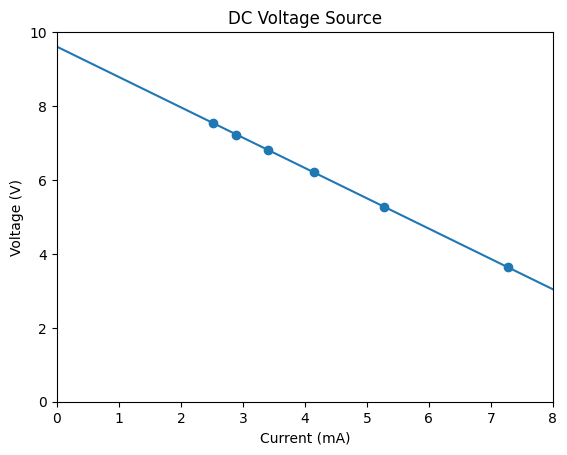

In [82]:
current = DC_voltage_source['Current']
voltage = DC_voltage_source['Voltage']
plt.figure()
plt.scatter(current, voltage)
y_fit, A, B = linear_fit(current, voltage)
x = np.linspace(0, 9, 100)
y = A + B*x
plt.plot(x, y)
plt.xlabel('Current (mA)')
plt.ylabel('Voltage (V)')
plt.title('DC Voltage Source')
plt.xlim(0,8)
plt.ylim(0,10)
print("slope is", B, "so output resistance is ", -1000*B, "output voltage is ", A)
plt.show()

phase slope is 35533.8466323814 mean phase is  -85.95454545454545


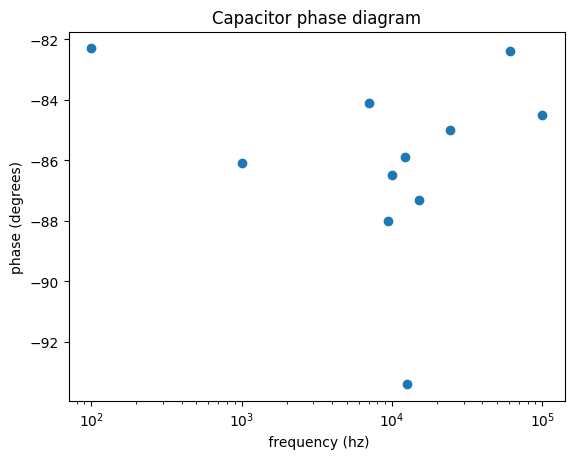

intercept is  -2.6029769731603163 slope is  68754666.36412233 Capacitance is 1.4544467348645613e-08


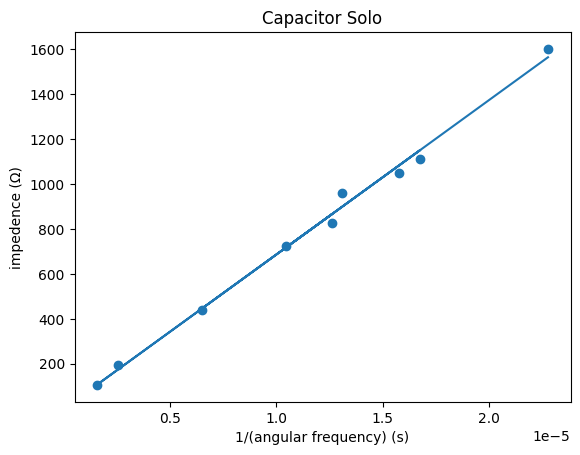

In [83]:
f = Capacitor_solo['frequency']
z = Capacitor_solo['impedence']
phase  = Capacitor_solo_complete['Phase(degrees)']
x = Capacitor_solo_complete['Frequency(hz)']
plt.figure()
plt.scatter(x, phase)
y_fit, A, B = linear_fit(x, phase)
print("phase slope is", 1/B, "mean phase is ", np.mean(phase))
#plt.plot(x, y_fit)
plt.xlabel(' frequency (hz)')
plt.ylabel('phase (degrees)')
plt.xscale('log')
plt.title('Capacitor phase diagram')
plt.show()
plt.figure()
x = 1/(2*np.pi*f)
#x = 2*np.pi*f
y_fit, A, B = linear_fit(x, z)
print("intercept is ", A, "slope is ", B, "Capacitance is", 1/B)
plt.scatter(x, z)
plt.plot(x, y_fit)
plt.xlabel('1/(angular frequency) (s)')
plt.ylabel('impedence (Ω)')
plt.title('Capacitor Solo')
plt.show()


phase slope is 68754666.36412233 mean phase is  -109.09


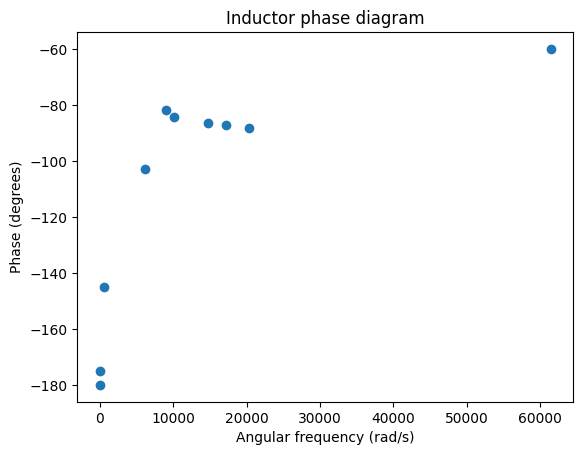

intercept is  -1.8982787401965624 slope is  0.016771245074040216 Inductance is 0.016771245074040216


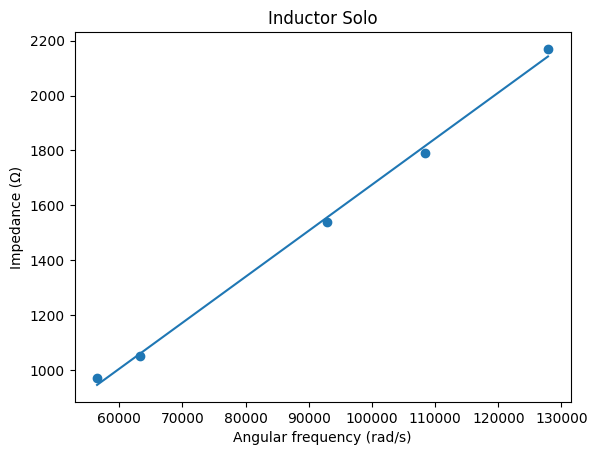

In [84]:
f = Inductor_solo['frequency']
z = Inductor_solo['impedence']
phase  = Inductor_solo_complete['Phase(Degrees)']
x = Inductor_solo_complete['frequency(hz)']
plt.figure()
plt.scatter(x, phase)
#y_fit, A, B = linear_fit(x, phase)
print("phase slope is", B, "mean phase is ", np.mean(phase))
#plt.plot(x, y_fit)
plt.xlabel('Angular frequency (rad/s)')
plt.ylabel('Phase (degrees)')
plt.title('Inductor phase diagram')
plt.show()
x = 2*np.pi*f
y_fit, A, B = linear_fit(x, z)
print("intercept is ", A, "slope is ", B, "Inductance is", B)
plt.figure()
plt.scatter(x, z)
plt.plot(x, y_fit)
plt.xlabel('Angular frequency (rad/s)')
plt.ylabel('Impedance (Ω)')
plt.title('Inductor Solo')
plt.show()


intercept is  1200.443485086692 slope is  4.414336758870295e-05 Resistance is 1205.4 % diff is  0.049776007964153726


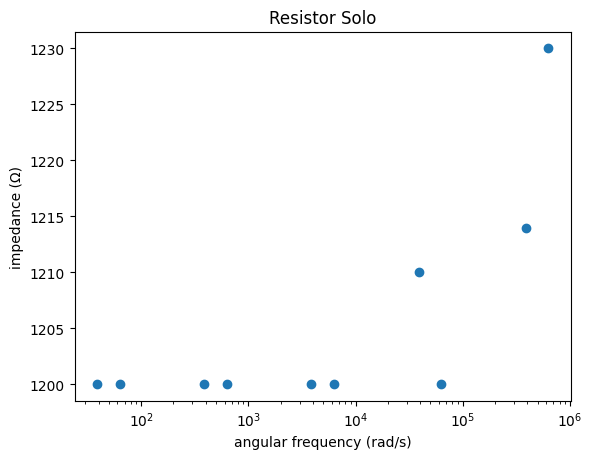

phase slope is 7.455005077393918e-06 mean phase is  1.5962 standard deviation is  3.008895305589744


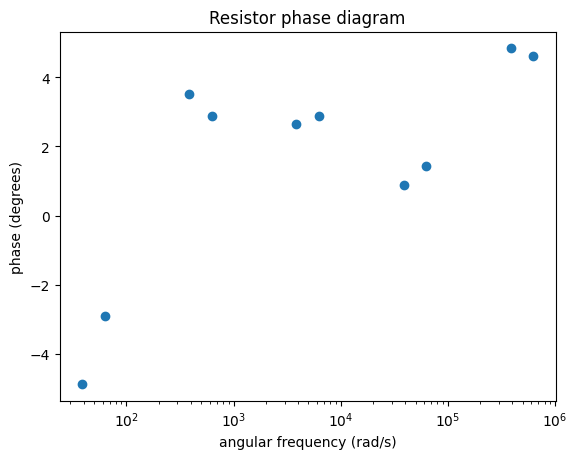

In [85]:
f = Resistor_solo['frequency']
z = Resistor_solo['impedence']
phase  = Resistor_solo['phase']
x = 2*np.pi*f
y_fit, A, B = linear_fit(x, z)
print("intercept is ", A, "slope is ", B, "Resistance is", np.mean(z), "% diff is ", (1206 - np.mean(z))/np.mean(z)*100)
plt.figure()
plt.scatter(x, z)
#plt.plot(x, y_fit)
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('impedance (Ω)')
plt.title('Resistor Solo')
plt.xscale('log')
plt.show()
plt.figure()
plt.scatter(x, phase)
y_fit, A, B = linear_fit(x, phase)
print("phase slope is", B, "mean phase is ", np.mean(phase), "standard deviation is ", standard_deviation(phase))
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('phase (degrees)')
plt.xscale('log')
plt.title('Resistor phase diagram')
plt.show()

phase slope is 0.00012074734265443609 mean phase is 


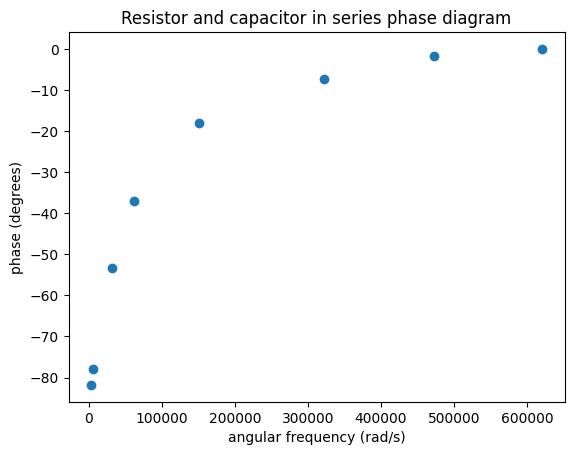

intercept is  831678.5885883217 slope is  4525813112271520.0
phase slope is 4525813112271520.0 Capacitance is  1.4864547454995575e-08


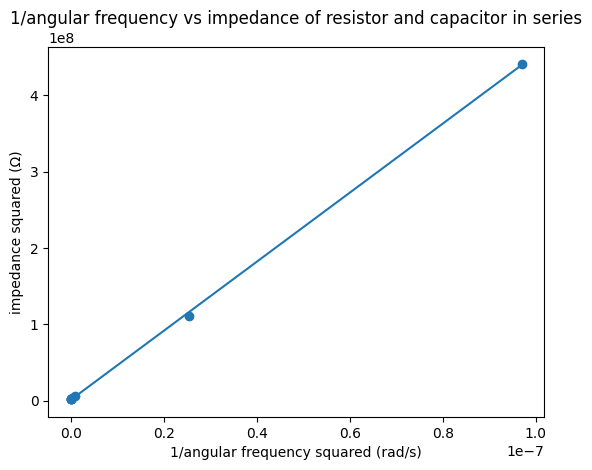

In [86]:
f = Resistor_and_cap_series['Frequency(hz)']
z = Resistor_and_cap_series['Impedance(Ohms)']
phase  = Resistor_and_cap_series['Phase(Degrees)']
x = 2*np.pi*f
plt.figure()
plt.scatter(x, phase)
y_fit, A, B = linear_fit(x, phase)
print("phase slope is", B, "mean phase is ")
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('phase (degrees)')
plt.title('Resistor and capacitor in series phase diagram')
plt.show()
y_fit, A, B = linear_fit(1/x**2, z**2)
print("intercept is ", A, "slope is ", B)
plt.figure()
plt.scatter(1/x**2, z**2)
plt.plot(1/x**2, y_fit)
print("phase slope is", B, "Capacitance is ", 1/np.sqrt(B))
plt.xlabel('1/angular frequency squared (rad/s)')
plt.ylabel('impedance squared (Ω)')
plt.title('1/angular frequency vs impedance of resistor and capacitor in series')
plt.show()


phase slope is 0.00041787515689677515 mean phase is 


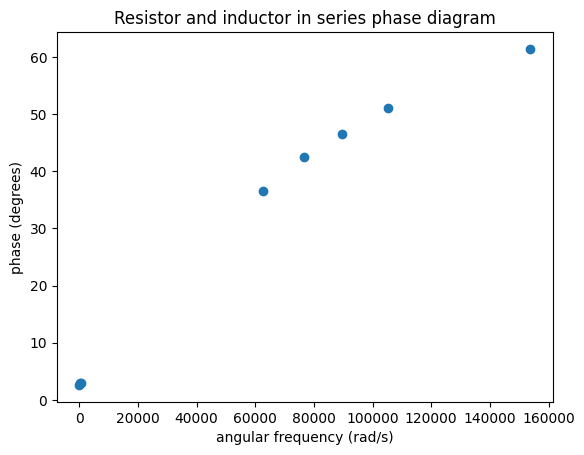

intercept is  1772081.9514090968 slope is  0.00024172433992503974
phase slope is 0.00024172433992503974 Inductance is  0.015547486611187024


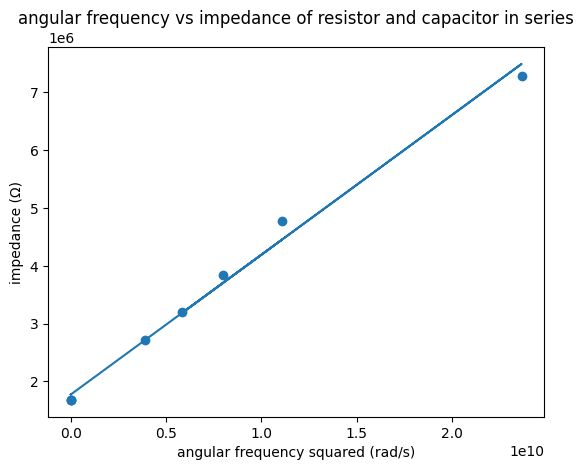

In [87]:
f = Resistor_and_ind_series['Frequency(hz)']
z = Resistor_and_ind_series['Impedance(Ohms)']
phase  = Resistor_and_ind_series['Phase(Degrees)']
x = 2*np.pi*f
plt.figure()
plt.scatter(x, phase)
y_fit, A, B = linear_fit(x, phase)
print("phase slope is", B, "mean phase is ")
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('phase (degrees)')
plt.title('Resistor and inductor in series phase diagram')
plt.show()
y_fit, A, B = linear_fit(x**2, z**2)
print("intercept is ", A, "slope is ", B)
plt.figure()
plt.scatter(x**2, z**2)
plt.plot(x**2, y_fit)
print("phase slope is", B, "Inductance is ", np.sqrt(B))
plt.xlabel('angular frequency squared (rad/s)')
plt.ylabel('impedance (Ω)')
plt.title('angular frequency vs impedance of resistor and capacitor in series')
plt.show()

phase slope is 1.3519500809629975e-07 minimum value is 65533.622753883086


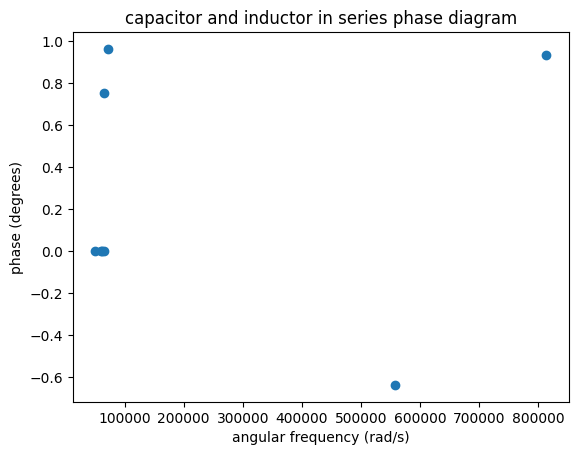

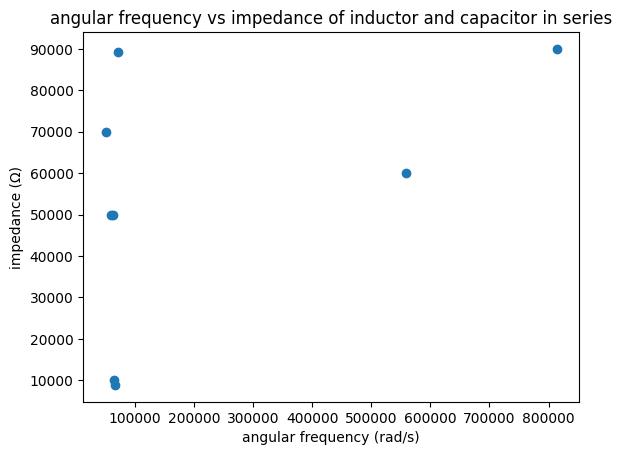

In [88]:
f = ind_cap_series['Frequency(hz)']
z = (ind_cap_series['Voltage 1(V)']/ind_cap_series['Voltage 2(V)'])*ind_cap_series['Impedance(Ohms)']
phase  = ind_cap_series['Phase(Degrees)']
x = 2*np.pi*f
plt.figure()
plt.scatter(x, phase)
y_fit, A, B = linear_fit(x, phase)
print("phase slope is", B, "minimum value is", 10430*2*np.pi)
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('phase (degrees)')
plt.title('capacitor and inductor in series phase diagram')
plt.show()
plt.figure()
plt.scatter(x, z)
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('impedance (Ω)')
plt.title('angular frequency vs impedance of inductor and capacitor in series')
plt.show()

phase slope is -4.6328372618457446e-05 maximum value is  59614.86219451991


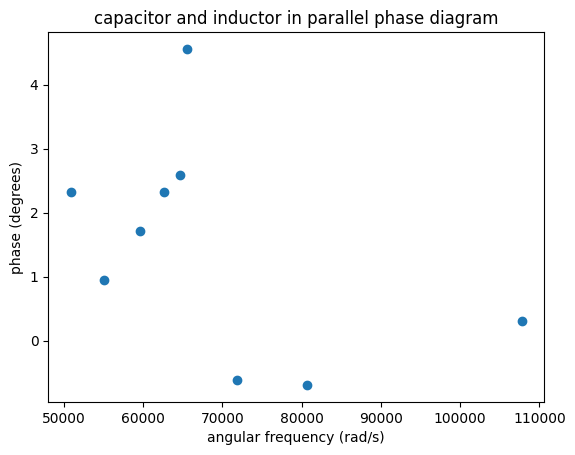

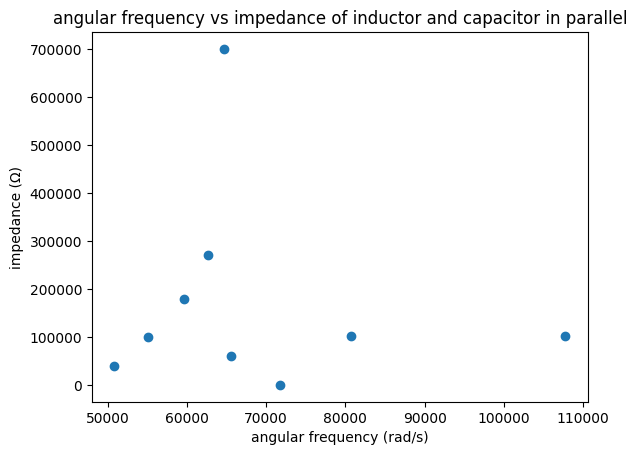

In [89]:
f = ind_cap_parallel['Frequency(hz)']
z = (ind_cap_parallel['Voltage 1(V)']/ind_cap_parallel['Voltage 2(V)'])*ind_cap_parallel['Impedance(Ohms)']
phase  = ind_cap_parallel['Phase(Degrees)']
x = 2*np.pi*f
plt.figure()
plt.scatter(x, phase)
y_fit, A, B = linear_fit(x, phase)
print("phase slope is", B, "maximum value is ", 9488*2*np.pi)
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('phase (degrees)')
plt.title('capacitor and inductor in parallel phase diagram')
plt.show()
plt.figure()
plt.scatter(x, z)
plt.xlabel('angular frequency (rad/s)')
plt.ylabel('impedance (Ω)')
plt.title('angular frequency vs impedance of inductor and capacitor in parallel')
plt.show()